### Exploratory Data Analysis

This notebook explores the Red Wine Quality dataset through
initial data inspection, descriptive statistics and exploratory
visualizations.

In [2]:
import numpy as np
import pandas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

#### Data Loading

In [6]:
df = pandas.read_csv("../data/raw/winequality-red.csv", sep=',')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


The dataset contains 1,599 observations and 12 columns, including 11 physicochemical features and one integer target variable (`quality`). No missing values are indicated.

Missing Values and Duplicates

In [10]:
print("Missing values:")
display(df.isnull().sum())

print(f"\nDuplicate rows: {df.duplicated().sum()}")

Missing values:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


Duplicate rows: 240


A total of 240 duplicate rows were identified. These will be removed during the preprocessing stage.

#### Descriptive Statistics

In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


Some variables, such as residual sugar, chlorides, and sulfur dioxide, show relatively high maximum values compared to their upper quartiles, suggesting potential outliers and positively skewed distributions.

No observations or features will be removed at this stage. The statistics will also be recalculated after duplicate removal during preprocessing.

#### Univariate Analysis

Explore the distributions of the physicochemical attributes
and the original quality scores.

Quality Distribution

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

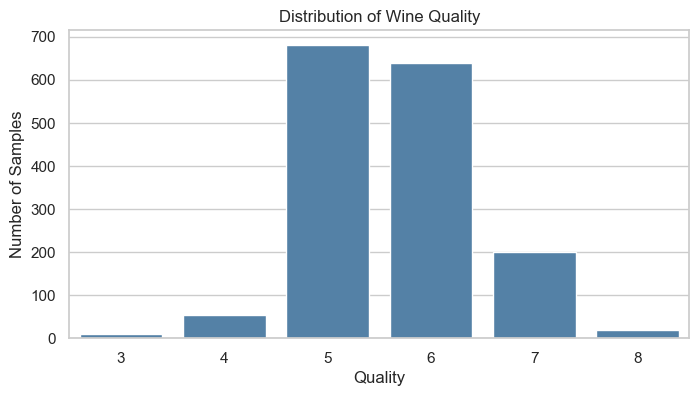

In [12]:
quality_counts = df["quality"].value_counts().sort_index()

display(quality_counts)

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="quality", color="steelblue")

plt.title("Distribution of Wine Quality")
plt.xlabel("Quality")
plt.ylabel("Number of Samples")
plt.show()

The quality scores are concentrated mainly around 5 and 6, while extreme ratings are considerably less frequent. This imbalance will be considered during model training, where different strategies will be compared to assess their impact on classification performance.

Feature distributions

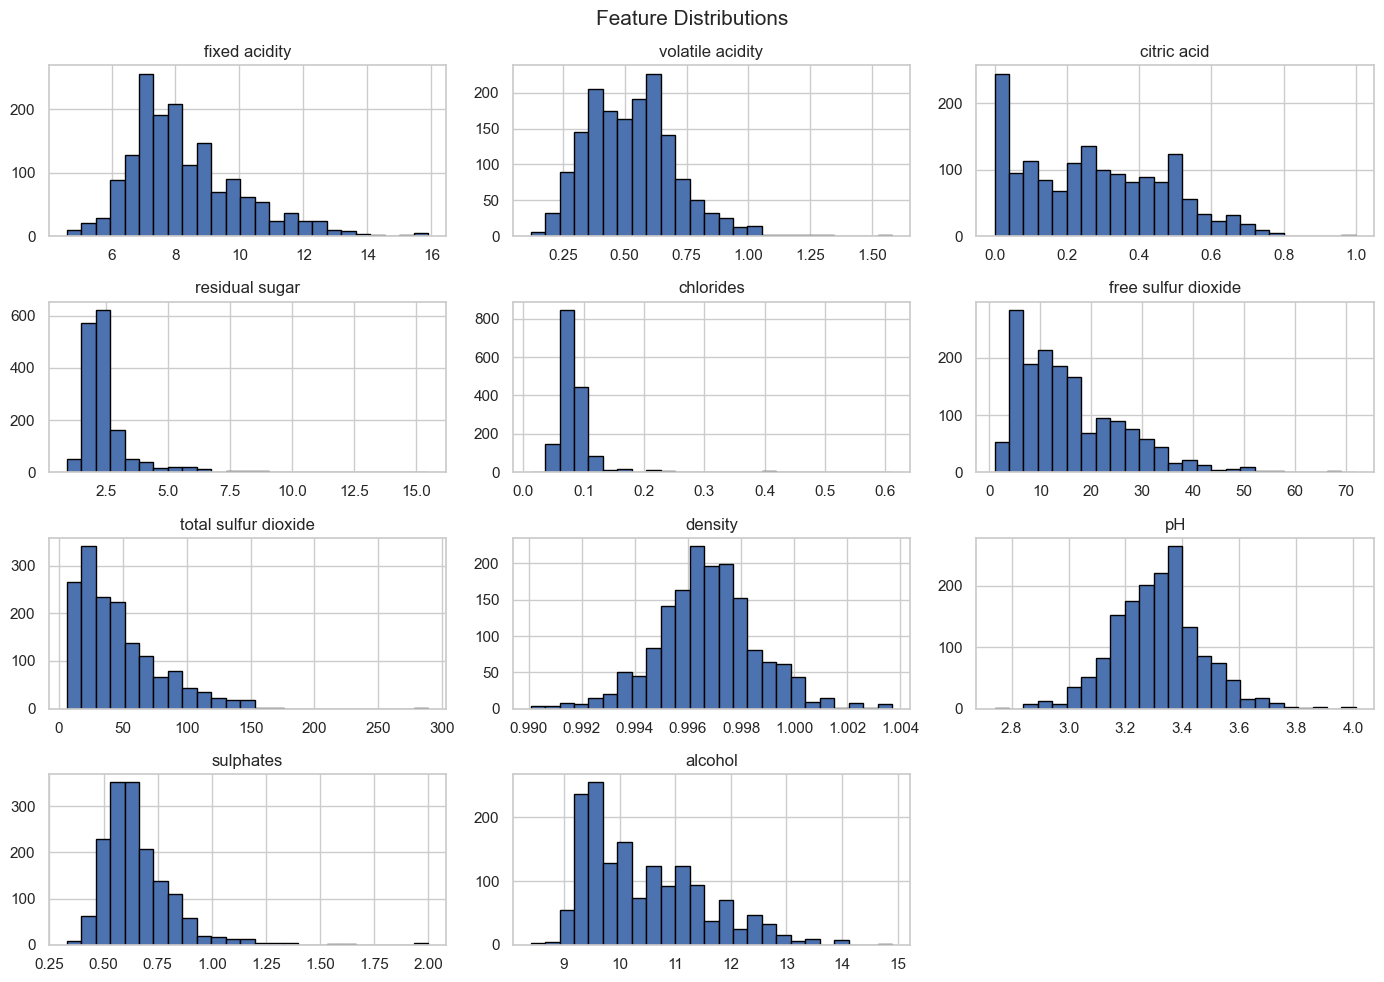

In [13]:
df.drop(columns="quality").hist(figsize=(14, 10), bins=25, edgecolor="black")

plt.suptitle("Feature Distributions", fontsize=15)
plt.tight_layout()
plt.show()

#### Outlier Analysis

Use boxplots to identify potential outliers in the numerical
attributes. These observations will be examined before deciding
whether any treatment is necessary.

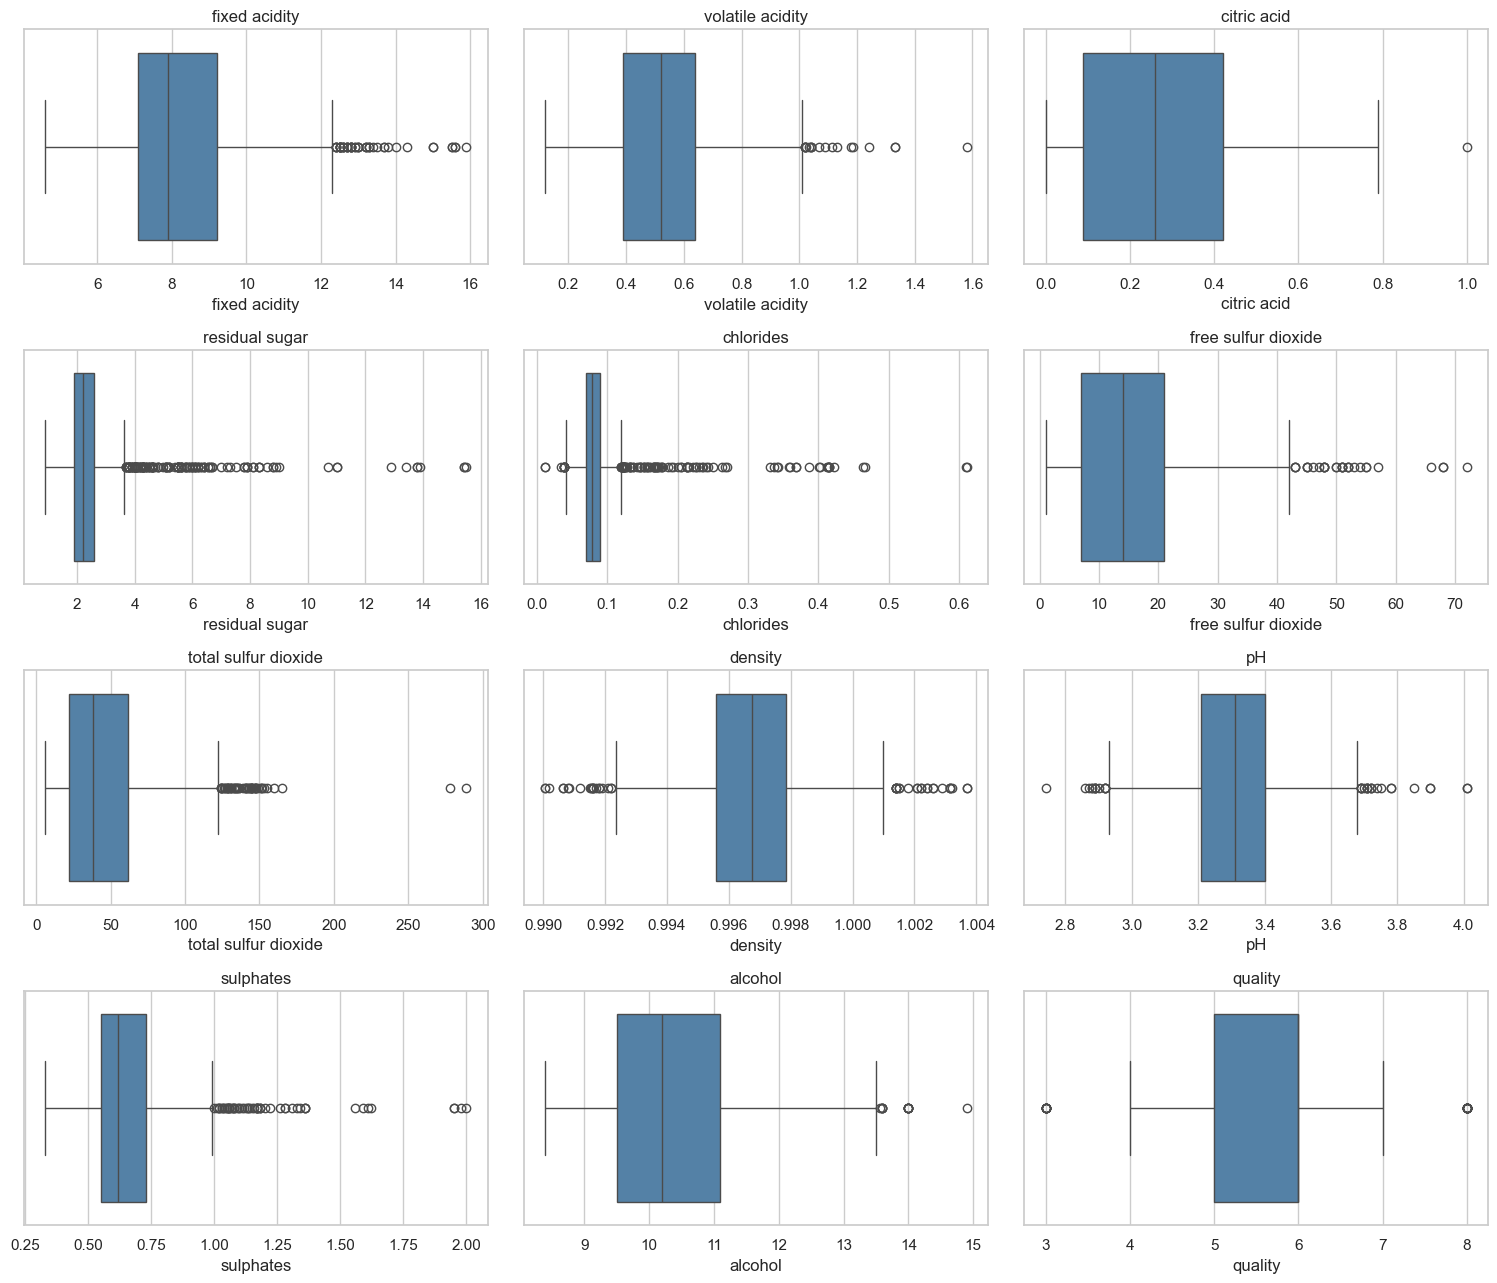

In [14]:
fig, axes = plt.subplots(4, 3, figsize=(15, 13))
axes = axes.flatten()

for i, column in enumerate(df.columns):
    sns.boxplot(data=df, x=column, ax=axes[i], color="steelblue")
    axes[i].set_title(column)

for ax in axes[len(df.columns):]:
    ax.remove()

plt.tight_layout()
plt.show()

Potential outliers in several features, particularly residual sugar, chlorides, sulfur dioxide, and sulphates. Some variables also show observations at both distribution extremes.

These values will not be removed at this stage. Their treatment will be considered during preprocessing, taking into account their impact on the data and whether they represent valid observations.

#### Correlation Analysis

Examine the linear correlations between the numerical variables
and their relationships with wine quality.

Correlation Marix

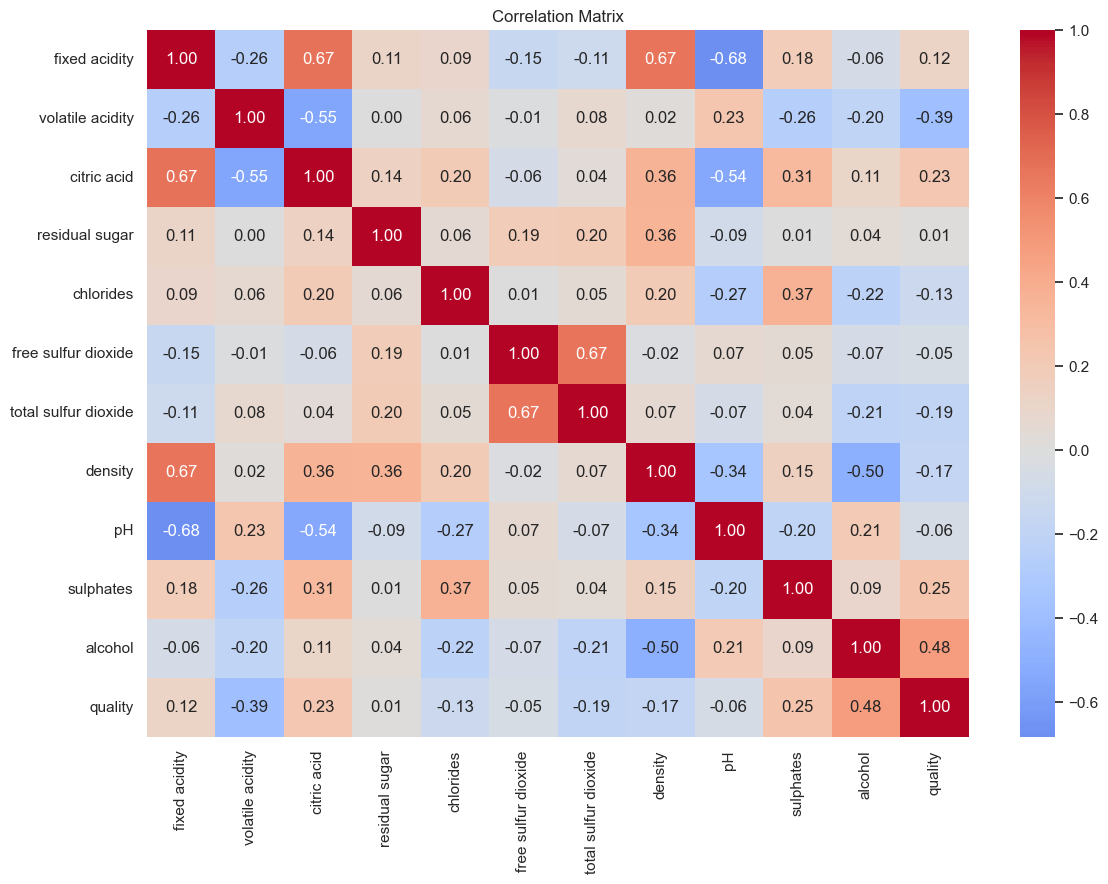

In [15]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

Correlation with quality

In [16]:
quality_correlations = (
    correlation_matrix["quality"]
    .drop("quality")
    .sort_values(ascending=False)
)

display(quality_correlations)

alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64

Alcohol (0.476) shows the strongest positive correlation with quality, while volatile acidity (-0.391) presents the strongest negative correlation. Sulphates (0.251) and citric acid (0.226) also show positive associations.

The remaining features exhibit relatively weak correlations with quality. Some predictor variables show stronger correlations with each other, which will be considered in the subsequent analysis. These relationships do not imply causation.